# 03 · Train / validation / internal test split

Splits the 27,000 EuroSAT images into three parts, with every class in the same proportion:

| Split | Share | Used for |
|---|---|---|
| `train` | 70% | fitting the models |
| `val` | 15% | early stopping and tuning |
| `test` | 15% | internal hold-out, only for comparing finished models |

The Kaggle test set (Level-2A) remains the real measure of how well a model handles the domain shift.
The internal test set can only show how well a model learned EuroSAT itself.

**Neighbouring patches.** `01_eda.ipynb` showed that half of all patches touch another patch, and
almost always one of the same class. With a purely random split, a model could be tested on a
patch whose neighbour it saw in training, which inflates the internal score. So neighbouring patches
are grouped and every group goes into one split as a whole.

The result is saved to `artifacts/splits/split_seed42.csv` and committed to Git, so the whole team uses the same split.

## 1 · Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

sys.path.insert(0, str(Path.cwd().parent))
from src.data import CLASSES, PROJECT_ROOT, SPLITS_DIR, train_metadata
from src.plot_style import SPLIT_COLORS, apply_style

apply_style()

SEED = 42
TOUCH_DISTANCE_M = 700  # patches are 640 m wide, so centres closer than this touch

meta = train_metadata()

# Leave out images marked for removal in 02_data_quality.ipynb (none so far)
flags = pd.read_csv(PROJECT_ROOT / "artifacts" / "quality_flags.csv")
removed = meta["path"].isin(flags.loc[flags["remove"], "path"])
print(f"Removed after quality review: {removed.sum()}")
all_meta, meta = meta, meta[~removed].reset_index(drop=True)
meta.head()

Removed after quality review: 0


,path,label,label_id,lon,lat
0,AnnualCrop/AnnualCrop_135.tif,AnnualCrop,0,16.219873,48.422954
1,AnnualCrop/AnnualCrop_692.tif,AnnualCrop,0,10.825052,48.228294
2,AnnualCrop/AnnualCrop_2218.tif,AnnualCrop,0,4.015476,48.453540
3,AnnualCrop/AnnualCrop_2679.tif,AnnualCrop,0,9.768976,57.101696
4,AnnualCrop/AnnualCrop_926.tif,AnnualCrop,0,2.702437,47.055198


## 2 · Group neighbouring patches

Two patches are linked if their centres are less than 700 m apart. Chains of linked patches form
one group (connected components of the neighbour graph).

In [2]:
# Approximate metres from longitude/latitude (accurate enough at a 700 m scale)
xy = np.c_[meta["lon"] * 111_320 * np.cos(np.deg2rad(meta["lat"])), meta["lat"] * 110_574]
tree = cKDTree(xy)
graph = tree.sparse_distance_matrix(tree, TOUCH_DISTANCE_M, output_type="coo_matrix")
n_groups, meta["group"] = connected_components(graph, directed=False)

sizes = meta["group"].value_counts()
print(f"{n_groups:,} groups")
print(f"Single patches: {(sizes == 1).sum():,}, largest group: {sizes.max()} patches")
print(f"Groups containing more than one class: {(meta.groupby('group')['label'].nunique() > 1).sum()}")

17,042 groups
Single patches: 13,821, largest group: 139 patches
Groups containing more than one class: 143


## 3 · Split

`StratifiedGroupKFold` divides the groups into 20 folds of about 5% each, while keeping the class
proportions as equal as possible. Three folds become `test`, three become `val`, the other 14 `train`.

In [3]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.empty(len(meta), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(meta, meta["label"], groups=meta["group"])):
    fold[idx] = k

meta["split"] = np.select([fold < 3, fold < 6], ["test", "val"], "train")

table = meta.groupby(["label", "split"]).size().unstack()[["train", "val", "test"]]
table.loc["Total"] = table.sum()
share = (table.div(table.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %")
pd.concat([table, share], axis=1)

split,train,val,test,train %,val %,test %
label,,,,,,
AnnualCrop,2100,450,450,70.0,15.0,15.0
Forest,2100,450,450,70.0,15.0,15.0
HerbaceousVegetation,2100,450,450,70.0,15.0,15.0
Highway,1750,375,375,70.0,15.0,15.0
Industrial,1750,375,375,70.0,15.0,15.0
Pasture,1400,300,300,70.0,15.0,15.0
PermanentCrop,1750,375,375,70.0,15.0,15.0
Residential,2100,450,450,70.0,15.0,15.0
River,1750,375,375,70.0,15.0,15.0


## 4 · Check: class balance

Each class should have about the same share in every split.

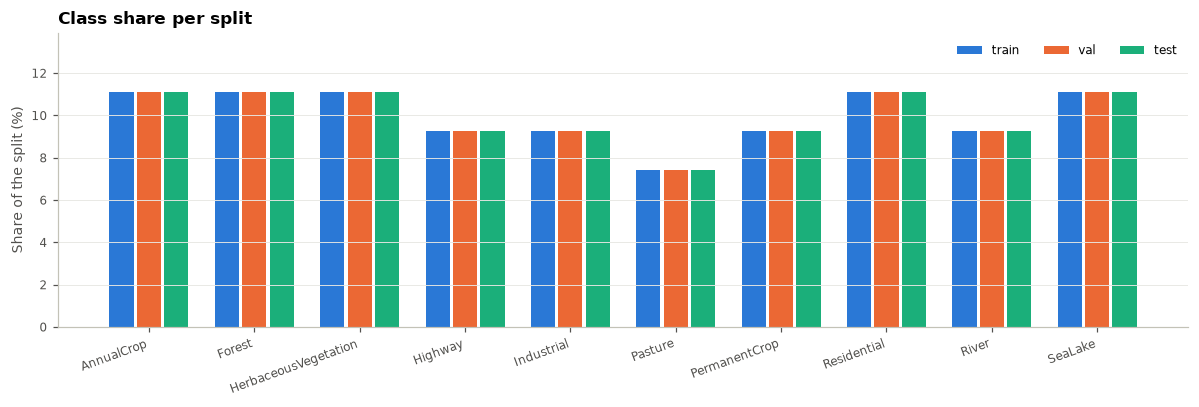

In [4]:
counts = meta.groupby(["label", "split"]).size().unstack()[["train", "val", "test"]].loc[CLASSES]
props = counts / counts.sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(CLASSES))
w = 0.26
for i, split in enumerate(["train", "val", "test"]):
    ax.bar(x + (i - 1) * w, props[split] * 100, width=w - 0.03, color=SPLIT_COLORS[split], label=split)
ax.set_xticks(x, CLASSES, rotation=20, ha="right")
ax.set_ylabel("Share of the split (%)")
ax.set_ylim(0, props.values.max() * 100 * 1.25)
ax.set_title("Class share per split", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

## 5 · Check: leakage compared with a random split

For each internal test image: does a training image touch it? A random split with the same
proportions is shown for comparison.

In [5]:
def leaked_share(split_labels):
    """Share of internal-test images with a touching neighbour in the train split."""
    is_train = split_labels == "train"
    train_tree = cKDTree(xy[is_train])
    test_xy = xy[split_labels == "test"]
    dist, _ = train_tree.query(test_xy, k=1)
    return (dist < TOUCH_DISTANCE_M).mean()

rest, test_rows = train_test_split(meta.index, test_size=0.15, stratify=meta["label"], random_state=SEED)
_, val_rows = train_test_split(rest, test_size=0.15 / 0.85, stratify=meta.loc[rest, "label"], random_state=SEED)
random_split = pd.Series("train", index=meta.index)
random_split[val_rows] = "val"
random_split[test_rows] = "test"

leak = pd.Series({
    "Random split": leaked_share(random_split.values),
    "Grouped split (used)": leaked_share(meta["split"].values),
})
print((leak * 100).round(1).astype(str) + " % of internal test images touch a training image")

Random split            40.2 % of internal test images touch a trainin...
Grouped split (used)    0.0 % of internal test images touch a training...
dtype: str


## 6 · Save

In [6]:
SPLITS_DIR.mkdir(exist_ok=True)
out = SPLITS_DIR / f"split_seed{SEED}.csv"
result = all_meta[["path", "label", "label_id"]].merge(meta[["path", "group", "split"]], on="path", how="left")
result["split"] = result["split"].fillna("removed")
result.to_csv(out, index=False)
print(f"Saved {out.relative_to(PROJECT_ROOT)}  ({len(result):,} rows)")
print(result["split"].value_counts().to_dict())

# Other notebooks load it with:
#   from src.data import load_split
#   split = load_split()          # columns: path, label, label_id, group, split ("removed" = excluded)

Saved artifacts/splits/split_seed42.csv  (27,000 rows)
{'train': 18900, 'test': 4050, 'val': 4050}
